In [59]:
files_to_check = [

    MODELS_DIR / "gan_generator.keras",
    MODELS_DIR / "gan_discriminator.keras",

    SYNTHETIC_DIR / "gan_fraud_synthetic.parquet",

    PROCESSED_DIR / "X_train_gan.parquet",
    PROCESSED_DIR / "y_train_gan.parquet",

    METRICS_DIR / "gan_training_history.csv",
    METRICS_DIR / "gan_feature_fidelity.csv",
    METRICS_DIR / "gan_summary.csv",

    FIGURES_DIR / "gan_training_losses.png",
    FIGURES_DIR / "gan_pca_iteration_1_vs_5000.png",
    FIGURES_DIR / "gan_pca_real_vs_synthetic.png"
]

for path in files_to_check:

    print(
        path.name,
        "→",
        path.exists()
    )

gan_generator.keras → True
gan_discriminator.keras → True
gan_fraud_synthetic.parquet → True
X_train_gan.parquet → True
y_train_gan.parquet → True
gan_training_history.csv → True
gan_feature_fidelity.csv → True
gan_summary.csv → True
gan_training_losses.png → True
gan_pca_iteration_1_vs_5000.png → True
gan_pca_real_vs_synthetic.png → True


In [58]:
gan_history.to_csv(
    METRICS_DIR / "gan_training_history.csv",
    index=False
)

gan_fidelity.to_csv(
    METRICS_DIR / "gan_feature_fidelity.csv",
    index=False
)

gan_summary.to_csv(
    METRICS_DIR / "gan_summary.csv",
    index=False
)

In [57]:
X_train_gan.to_parquet(
    PROCESSED_DIR / "X_train_gan.parquet",
    index=False
)

y_train_gan.to_frame(
    name="Class"
).to_parquet(
    PROCESSED_DIR / "y_train_gan.parquet",
    index=False
)

In [56]:
gan_synthetic_df = (
    X_gan_synthetic.copy()
)

gan_synthetic_df["Class"] = 1

gan_synthetic_df.to_parquet(
    SYNTHETIC_DIR / "gan_fraud_synthetic.parquet",
    index=False
)

In [55]:
generator.save(
    MODELS_DIR / "gan_generator.keras"
)

discriminator.save(
    MODELS_DIR / "gan_discriminator.keras"
)

In [54]:
gan_summary = pd.DataFrame({
    "Mesure": [
        "Fraudes réelles utilisées",
        "Dimension du bruit",
        "Itérations GAN",
        "Fraudes synthétiques créées",
        "NaN synthétiques",
        "Inf synthétiques",
        "Doublons synthétiques",
        "Copies exactes",
        "Diversité réelle",
        "Diversité synthétique",
        "Ratio diversité GAN/Réel",
        "Erreur corrélation Spearman"
    ],
    "Valeur": [
        len(X_real_fraud),
        LATENT_DIM,
        N_STEPS,
        len(X_gan_synthetic),
        gan_nan,
        gan_inf,
        gan_duplicates,
        gan_exact_copies,
        real_diversity,
        synthetic_diversity,
        diversity_ratio,
        gan_corr_mae
    ]
})

display(gan_summary)

,Mesure,Valeur
0,Fraudes réelles utilisées,331.000000
1,Dimension du bruit,30.000000
2,Itérations GAN,5000.000000
3,Fraudes synthétiques créées,197946.000000
4,NaN synthétiques,0.000000
5,Inf synthétiques,0.000000
6,Doublons synthétiques,0.000000
7,Copies exactes,0.000000
8,Diversité réelle,0.926864
9,Diversité synthétique,0.927821


In [53]:
X_train_gan = pd.concat(
    [
        X_train.reset_index(drop=True),
        X_gan_synthetic
    ],
    ignore_index=True
)

y_gan_synthetic = pd.Series(
    np.ones(
        len(X_gan_synthetic),
        dtype=np.int64
    ),
    name="Class"
)

y_train_gan = pd.concat(
    [
        y_train.reset_index(drop=True),
        y_gan_synthetic
    ],
    ignore_index=True
)

print(
    y_train_gan
    .value_counts()
    .sort_index()
)

Class
0    198277
1    198277
Name: count, dtype: int64


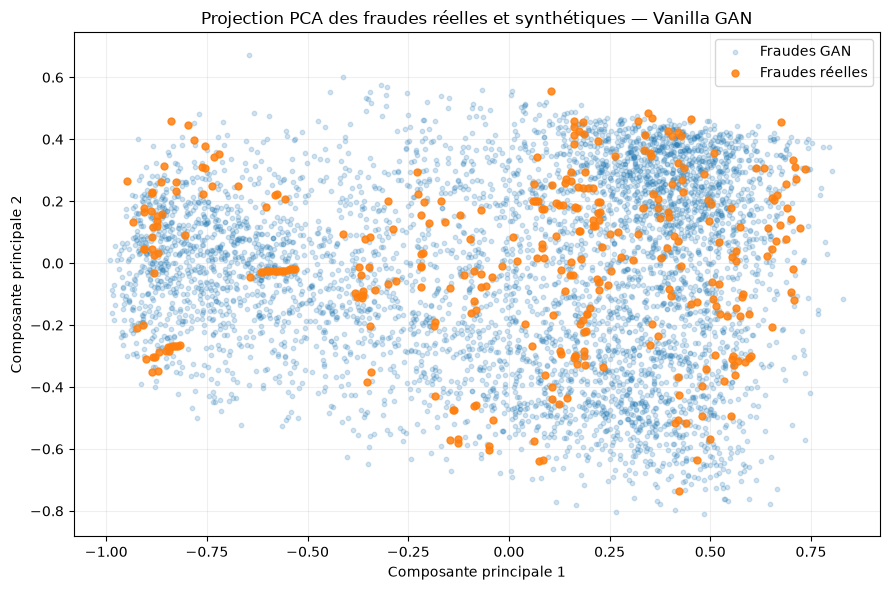

In [52]:
gan_vis = (
    X_gan_synthetic
    .sample(
        n=5000,
        random_state=42
    )
)

gan_vis_pca = pca_gan.transform(
    gan_vis
)

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.scatter(
    gan_vis_pca[:, 0],
    gan_vis_pca[:, 1],
    s=10,
    alpha=0.20,
    label="Fraudes GAN"
)

ax.scatter(
    real_pca[:, 0],
    real_pca[:, 1],
    s=25,
    alpha=0.85,
    label="Fraudes réelles"
)

ax.set_xlabel(
    "Composante principale 1"
)

ax.set_ylabel(
    "Composante principale 2"
)

ax.set_title(
    "Projection PCA des fraudes réelles et synthétiques — Vanilla GAN"
)

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "gan_pca_real_vs_synthetic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C:\Users\MSI\AppData\Local\Temp\ipykernel_32476\3499891300.py:83: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


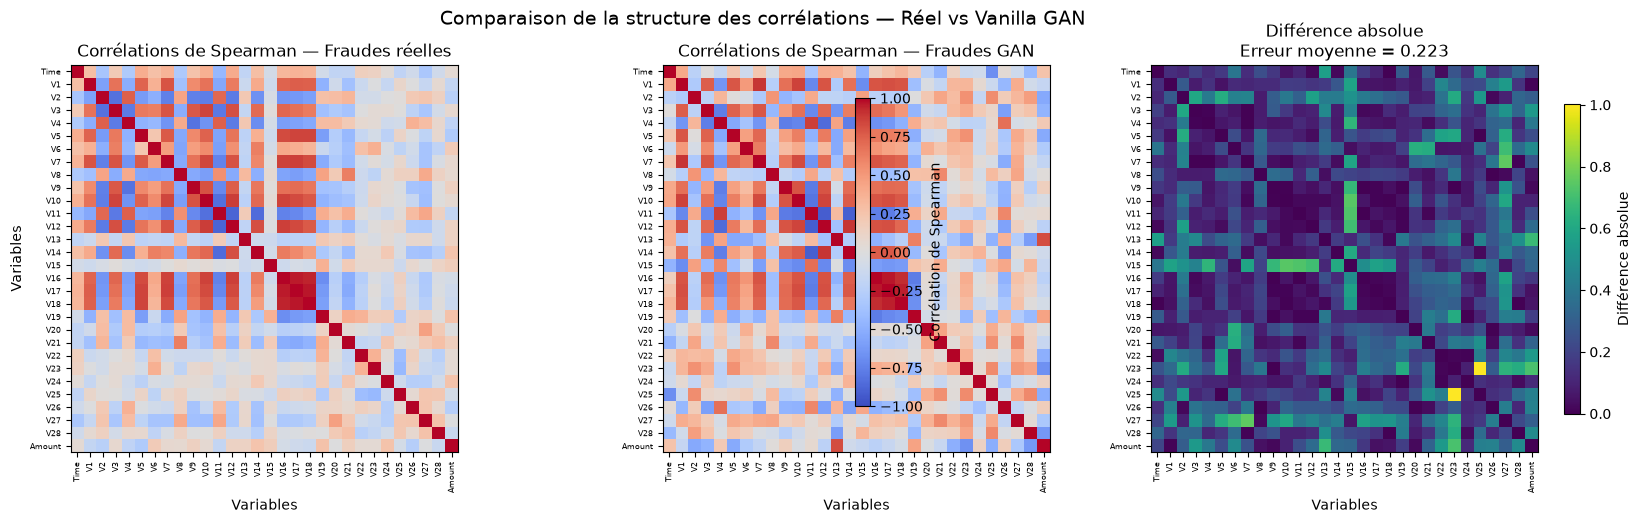

In [51]:
# Différence absolue entre les corrélations
corr_diff = np.abs(
    real_corr.to_numpy() - gan_corr.to_numpy()
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

# Fraudes réelles
im1 = axes[0].imshow(
    real_corr,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

axes[0].set_title("Corrélations de Spearman — Fraudes réelles")
axes[0].set_xlabel("Variables")
axes[0].set_ylabel("Variables")

# Fraudes GAN
im2 = axes[1].imshow(
    gan_corr,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

axes[1].set_title("Corrélations de Spearman — Fraudes GAN")
axes[1].set_xlabel("Variables")

# Différence
im3 = axes[2].imshow(
    corr_diff,
    vmin=0,
    vmax=corr_diff.max(),
    cmap="viridis"
)

axes[2].set_title(
    f"Différence absolue\nErreur moyenne = {gan_corr_mae:.3f}"
)
axes[2].set_xlabel("Variables")

feature_names = X_real_fraud.columns

for ax in axes:
    ax.set_xticks(range(len(feature_names)))
    ax.set_xticklabels(
        feature_names,
        rotation=90,
        fontsize=6
    )

    ax.set_yticks(range(len(feature_names)))
    ax.set_yticklabels(
        feature_names,
        fontsize=6
    )

fig.colorbar(
    im1,
    ax=axes[:2],
    shrink=0.8,
    label="Corrélation de Spearman"
)

fig.colorbar(
    im3,
    ax=axes[2],
    shrink=0.8,
    label="Différence absolue"
)

fig.suptitle(
    "Comparaison de la structure des corrélations — Réel vs Vanilla GAN",
    fontsize=14
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "gan_spearman_correlation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
gan_corr_sample = (
    X_gan_synthetic
    .sample(
        n=min(
            20000,
            len(X_gan_synthetic)
        ),
        random_state=42
    )
)

real_corr = (
    X_real_fraud
    .corr(method="spearman")
)

gan_corr = (
    gan_corr_sample
    .corr(method="spearman")
)

corr_difference = np.abs(
    real_corr.to_numpy()
    -
    gan_corr.to_numpy()
)

upper_triangle = np.triu_indices_from(
    corr_difference,
    k=1
)

gan_corr_mae = float(
    corr_difference[
        upper_triangle
    ].mean()
)

print(
    "Erreur moyenne des corrélations de Spearman :",
    gan_corr_mae
)

Erreur moyenne des corrélations de Spearman : 0.22295363183599334


In [49]:
gan_fidelity_results = []

for column in X_train.columns:

    real_values = (
        X_real_fraud[column]
        .to_numpy()
    )

    synthetic_values = (
        X_gan_synthetic[column]
        .to_numpy()
    )

    ks_stat = ks_2samp(
        real_values,
        synthetic_values
    ).statistic

    wasserstein = wasserstein_distance(
        real_values,
        synthetic_values
    )

    gan_fidelity_results.append({
        "Feature": column,
        "KS_Statistic": ks_stat,
        "Wasserstein_Distance": wasserstein
    })

gan_fidelity = pd.DataFrame(
    gan_fidelity_results
)

display(
    gan_fidelity
    .sort_values(
        "KS_Statistic",
        ascending=False
    )
    .head(10)
)

,Feature,KS_Statistic,Wasserstein_Distance
23,V23,0.299603,0.024606
28,V28,0.294891,0.017542
20,V20,0.265605,0.013616
8,V8,0.248499,0.025892
21,V21,0.229088,0.018175
2,V2,0.213335,0.017471
25,V25,0.200644,0.025545
3,V3,0.195045,0.030033
7,V7,0.194508,0.019603
27,V27,0.194029,0.019422


In [48]:
synthetic_diversity_sample = (
    X_gan_synthetic
    .sample(
        n=len(X_real_fraud),
        random_state=42
    )
)

real_pairwise = pdist(
    X_real_fraud.to_numpy()
)

synthetic_pairwise = pdist(
    synthetic_diversity_sample.to_numpy()
)

real_diversity = float(
    np.mean(real_pairwise)
)

synthetic_diversity = float(
    np.mean(synthetic_pairwise)
)

diversity_ratio = (
    synthetic_diversity
    /
    real_diversity
)

print(
    "Distance moyenne réelle :",
    real_diversity
)

print(
    "Distance moyenne synthétique :",
    synthetic_diversity
)

print(
    "Ratio de diversité GAN/Réel :",
    diversity_ratio
)

Distance moyenne réelle : 0.926863647990703
Distance moyenne synthétique : 0.927820654405221
Ratio de diversité GAN/Réel : 1.001032521252282


In [47]:
real_float32 = (
    X_real_fraud
    .astype(np.float32)
)

synthetic_float32 = (
    X_gan_synthetic
    .astype(np.float32)
)

real_hashes = set(
    pd.util.hash_pandas_object(
        real_float32,
        index=False
    ).tolist()
)

synthetic_hashes = (
    pd.util.hash_pandas_object(
        synthetic_float32,
        index=False
    )
)

gan_exact_copies = int(
    synthetic_hashes
    .isin(real_hashes)
    .sum()
)

print(
    "Copies exactes de fraudes réelles :",
    gan_exact_copies
)

Copies exactes de fraudes réelles : 0


In [46]:
gan_nan = int(
    X_gan_synthetic
    .isna()
    .sum()
    .sum()
)

gan_inf = int(
    np.isinf(
        X_gan_synthetic.to_numpy()
    ).sum()
)

gan_duplicates = int(
    X_gan_synthetic
    .duplicated()
    .sum()
)

print("NaN :", gan_nan)
print("Infini :", gan_inf)
print("Doublons exacts :", gan_duplicates)

print(
    "Minimum généré :",
    X_gan_synthetic.min().min()
)

print(
    "Maximum généré :",
    X_gan_synthetic.max().max()
)

NaN : 0
Infini : 0
Doublons exacts : 0
Minimum généré : 1.4692914e-06
Maximum généré : 0.9996242


In [45]:
gan_generated_array = generate_gan_samples(
    generator=generator,
    n_samples=N_SYNTHETIC_GAN,
    latent_dim=LATENT_DIM
)

X_gan_synthetic = pd.DataFrame(
    gan_generated_array,
    columns=X_train.columns
)

print(
    "Fraudes GAN générées :",
    X_gan_synthetic.shape
)

Fraudes GAN générées : (197946, 30)


In [44]:
def generate_gan_samples(
    generator,
    n_samples,
    latent_dim,
    batch_size=4096,
    seed=2026
):

    rng = np.random.default_rng(seed)

    generated_chunks = []

    for start in range(
        0,
        n_samples,
        batch_size
    ):

        current_batch = min(
            batch_size,
            n_samples - start
        )

        noise = rng.normal(
            size=(
                current_batch,
                latent_dim
            )
        ).astype(np.float32)

        generated = generator(
            noise,
            training=False
        ).numpy()

        generated_chunks.append(
            generated
        )

    return np.vstack(
        generated_chunks
    )

In [43]:
N_SYNTHETIC_GAN = 197_946

c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\MSI\Desktop\fraud_detection_memoire\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


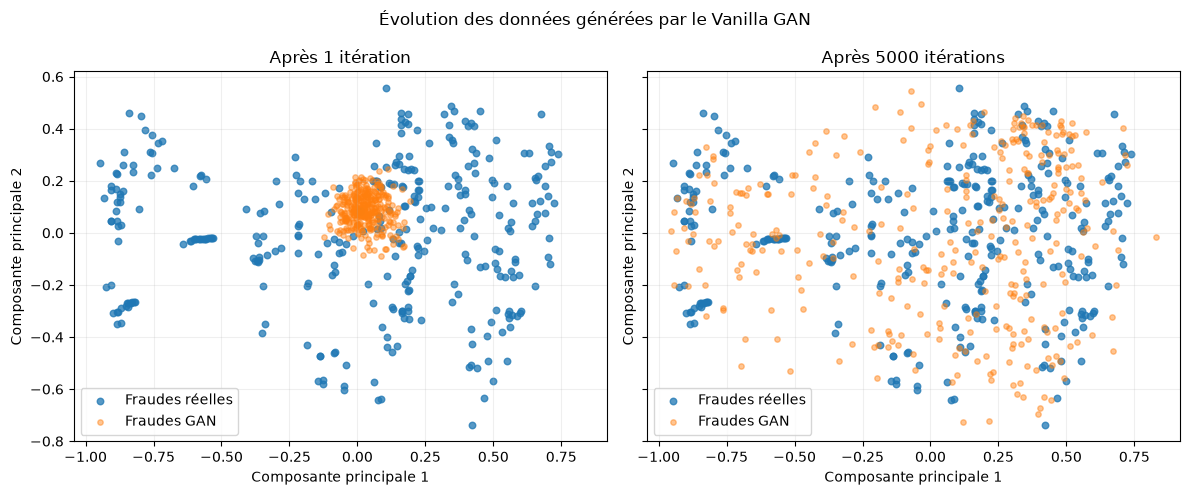

In [42]:
pca_snapshots = PCA(n_components=2)

# Le PCA apprend uniquement sur les vraies fraudes
real_pca_snap = pca_snapshots.fit_transform(
    X_real_fraud
)

snapshot_1_pca = pca_snapshots.transform(
    snapshots[1]
)

snapshot_5000_pca = pca_snapshots.transform(
    snapshots[5000]
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    sharex=True,
    sharey=True
)

# Itération 1
axes[0].scatter(
    real_pca_snap[:, 0],
    real_pca_snap[:, 1],
    s=22,
    alpha=0.75,
    label="Fraudes réelles"
)

axes[0].scatter(
    snapshot_1_pca[:, 0],
    snapshot_1_pca[:, 1],
    s=15,
    alpha=0.45,
    label="Fraudes GAN"
)

axes[0].set_title("Après 1 itération")

# Itération 5000
axes[1].scatter(
    real_pca_snap[:, 0],
    real_pca_snap[:, 1],
    s=22,
    alpha=0.75,
    label="Fraudes réelles"
)

axes[1].scatter(
    snapshot_5000_pca[:, 0],
    snapshot_5000_pca[:, 1],
    s=15,
    alpha=0.45,
    label="Fraudes GAN"
)

axes[1].set_title("Après 5000 itérations")

for ax in axes:
    ax.set_xlabel("Composante principale 1")
    ax.set_ylabel("Composante principale 2")
    ax.legend()
    ax.grid(alpha=0.2)

fig.suptitle(
    "Évolution des données générées par le Vanilla GAN"
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "gan_pca_iteration_1_vs_5000.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
print(snapshots.keys())

dict_keys([1, 100, 500, 1000, 2500, 5000])


In [40]:
files_to_check = [

    MODELS_DIR / "gan_generator.keras",
    MODELS_DIR / "gan_discriminator.keras",

    SYNTHETIC_DIR / "gan_fraud_synthetic.parquet",

    PROCESSED_DIR / "X_train_gan.parquet",
    PROCESSED_DIR / "y_train_gan.parquet",

    METRICS_DIR / "gan_training_history.csv",
    METRICS_DIR / "gan_feature_fidelity.csv",
    METRICS_DIR / "gan_summary.csv",

    FIGURES_DIR / "gan_training_losses.png",
    FIGURES_DIR / "gan_pca_iteration_1_vs_5000.png",
    FIGURES_DIR / "gan_pca_real_vs_synthetic.png"
]

for path in files_to_check:

    print(
        path.name,
        "→",
        path.exists()
    )

gan_generator.keras → True
gan_discriminator.keras → True
gan_fraud_synthetic.parquet → True
X_train_gan.parquet → True
y_train_gan.parquet → True
gan_training_history.csv → True
gan_feature_fidelity.csv → True
gan_summary.csv → True
gan_training_losses.png → True
gan_pca_iteration_1_vs_5000.png → False
gan_pca_real_vs_synthetic.png → True


In [39]:
gan_history.to_csv(
    METRICS_DIR / "gan_training_history.csv",
    index=False
)

gan_fidelity.to_csv(
    METRICS_DIR / "gan_feature_fidelity.csv",
    index=False
)

gan_summary.to_csv(
    METRICS_DIR / "gan_summary.csv",
    index=False
)

In [38]:
X_train_gan.to_parquet(
    PROCESSED_DIR / "X_train_gan.parquet",
    index=False
)

y_train_gan.to_frame(
    name="Class"
).to_parquet(
    PROCESSED_DIR / "y_train_gan.parquet",
    index=False
)

In [37]:
gan_synthetic_df = (
    X_gan_synthetic.copy()
)

gan_synthetic_df["Class"] = 1

gan_synthetic_df.to_parquet(
    SYNTHETIC_DIR / "gan_fraud_synthetic.parquet",
    index=False
)

In [36]:
generator.save(
    MODELS_DIR / "gan_generator.keras"
)

discriminator.save(
    MODELS_DIR / "gan_discriminator.keras"
)

In [35]:
gan_summary = pd.DataFrame({
    "Mesure": [
        "Fraudes réelles utilisées",
        "Dimension du bruit",
        "Itérations GAN",
        "Fraudes synthétiques créées",
        "NaN synthétiques",
        "Inf synthétiques",
        "Doublons synthétiques",
        "Copies exactes",
        "Diversité réelle",
        "Diversité synthétique",
        "Ratio diversité GAN/Réel",
        "Erreur corrélation Spearman"
    ],
    "Valeur": [
        len(X_real_fraud),
        LATENT_DIM,
        N_STEPS,
        len(X_gan_synthetic),
        gan_nan,
        gan_inf,
        gan_duplicates,
        gan_exact_copies,
        real_diversity,
        synthetic_diversity,
        diversity_ratio,
        gan_corr_mae
    ]
})

display(gan_summary)

,Mesure,Valeur
0,Fraudes réelles utilisées,331.000000
1,Dimension du bruit,30.000000
2,Itérations GAN,5000.000000
3,Fraudes synthétiques créées,197946.000000
4,NaN synthétiques,0.000000
5,Inf synthétiques,0.000000
6,Doublons synthétiques,0.000000
7,Copies exactes,0.000000
8,Diversité réelle,0.926864
9,Diversité synthétique,0.927821


In [34]:
X_train_gan = pd.concat(
    [
        X_train.reset_index(drop=True),
        X_gan_synthetic
    ],
    ignore_index=True
)

y_gan_synthetic = pd.Series(
    np.ones(
        len(X_gan_synthetic),
        dtype=np.int64
    ),
    name="Class"
)

y_train_gan = pd.concat(
    [
        y_train.reset_index(drop=True),
        y_gan_synthetic
    ],
    ignore_index=True
)

print(
    y_train_gan
    .value_counts()
    .sort_index()
)

Class
0    198277
1    198277
Name: count, dtype: int64


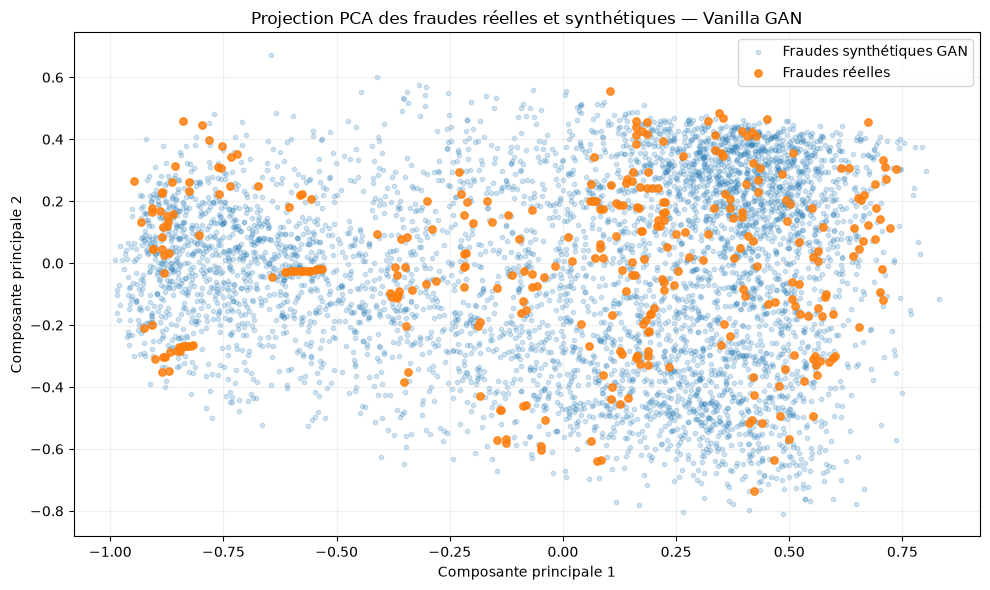

In [33]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.scatter(
    gan_pca[:, 0],
    gan_pca[:, 1],
    s=10,
    alpha=0.20,
    label="Fraudes synthétiques GAN"
)

ax.scatter(
    real_pca[:, 0],
    real_pca[:, 1],
    s=28,
    alpha=0.85,
    label="Fraudes réelles"
)

ax.set_title(
    "Projection PCA des fraudes réelles et synthétiques — Vanilla GAN"
)

ax.set_xlabel("Composante principale 1")
ax.set_ylabel("Composante principale 2")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "gan_pca_real_vs_synthetic.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# Échantillon GAN uniquement pour la visualisation
gan_vis = (
    X_gan_synthetic
    .sample(
        n=5000,
        random_state=42
    )
    .reset_index(drop=True)
)

# 1. Le PCA apprend UNIQUEMENT sur les fraudes réelles
pca_gan = PCA(n_components=2)

real_pca = pca_gan.fit_transform(
    X_real_fraud
)

# 2. Les données GAN sont seulement projetées
gan_pca = pca_gan.transform(
    gan_vis
)

print(
    "Variance expliquée par les deux composantes :",
    pca_gan.explained_variance_ratio_.sum()
)

Variance expliquée par les deux composantes : 0.639807065536427


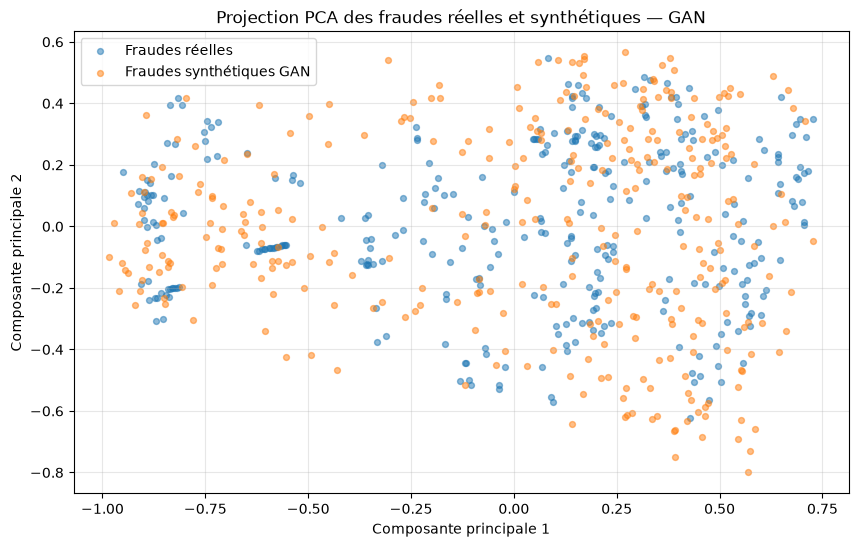

In [31]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# 1) Préparer un échantillon visuel de fraudes réelles
real_vis = X_real_fraud.sample(
    n=min(len(X_real_fraud), 331),
    random_state=42
).reset_index(drop=True)

# 2) Préparer un échantillon visuel de fraudes synthétiques GAN
gan_vis = X_gan_synthetic.sample(
    n=min(len(X_gan_synthetic), 331),
    random_state=42
).reset_index(drop=True)

# 3) Construire un PCA sur l’ensemble combiné
combined_vis = pd.concat([real_vis, gan_vis], axis=0).reset_index(drop=True)

pca_gan = PCA(n_components=2, random_state=42)
combined_pca = pca_gan.fit_transform(combined_vis)

# 4) Séparer les projections
real_vis_pca = combined_pca[:len(real_vis)]
gan_vis_pca = combined_pca[len(real_vis):]

# 5) Affichage
plt.figure(figsize=(10, 6))

plt.scatter(
    real_vis_pca[:, 0],
    real_vis_pca[:, 1],
    alpha=0.5,
    label="Fraudes réelles",
    s=18
)

plt.scatter(
    gan_vis_pca[:, 0],
    gan_vis_pca[:, 1],
    alpha=0.5,
    label="Fraudes synthétiques GAN",
    s=18
)

plt.title("Projection PCA des fraudes réelles et synthétiques — GAN")
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [29]:
gan_corr_sample = (
    X_gan_synthetic
    .sample(
        n=min(
            20000,
            len(X_gan_synthetic)
        ),
        random_state=42
    )
)

real_corr = (
    X_real_fraud
    .corr(method="spearman")
)

gan_corr = (
    gan_corr_sample
    .corr(method="spearman")
)

corr_difference = np.abs(
    real_corr.to_numpy()
    -
    gan_corr.to_numpy()
)

upper_triangle = np.triu_indices_from(
    corr_difference,
    k=1
)

gan_corr_mae = float(
    corr_difference[
        upper_triangle
    ].mean()
)

print(
    "Erreur moyenne des corrélations de Spearman :",
    gan_corr_mae
)

Erreur moyenne des corrélations de Spearman : 0.22295363183599334


In [28]:
gan_fidelity_results = []

for column in X_train.columns:

    real_values = (
        X_real_fraud[column]
        .to_numpy()
    )

    synthetic_values = (
        X_gan_synthetic[column]
        .to_numpy()
    )

    ks_stat = ks_2samp(
        real_values,
        synthetic_values
    ).statistic

    wasserstein = wasserstein_distance(
        real_values,
        synthetic_values
    )

    gan_fidelity_results.append({
        "Feature": column,
        "KS_Statistic": ks_stat,
        "Wasserstein_Distance": wasserstein
    })

gan_fidelity = pd.DataFrame(
    gan_fidelity_results
)

display(
    gan_fidelity
    .sort_values(
        "KS_Statistic",
        ascending=False
    )
    .head(10)
)

,Feature,KS_Statistic,Wasserstein_Distance
23,V23,0.299603,0.024606
28,V28,0.294891,0.017542
20,V20,0.265605,0.013616
8,V8,0.248499,0.025892
21,V21,0.229088,0.018175
2,V2,0.213335,0.017471
25,V25,0.200644,0.025545
3,V3,0.195045,0.030033
7,V7,0.194508,0.019603
27,V27,0.194029,0.019422


In [27]:
synthetic_diversity_sample = (
    X_gan_synthetic
    .sample(
        n=len(X_real_fraud),
        random_state=42
    )
)

real_pairwise = pdist(
    X_real_fraud.to_numpy()
)

synthetic_pairwise = pdist(
    synthetic_diversity_sample.to_numpy()
)

real_diversity = float(
    np.mean(real_pairwise)
)

synthetic_diversity = float(
    np.mean(synthetic_pairwise)
)

diversity_ratio = (
    synthetic_diversity
    /
    real_diversity
)

print(
    "Distance moyenne réelle :",
    real_diversity
)

print(
    "Distance moyenne synthétique :",
    synthetic_diversity
)

print(
    "Ratio de diversité GAN/Réel :",
    diversity_ratio
)

Distance moyenne réelle : 0.926863647990703
Distance moyenne synthétique : 0.927820654405221
Ratio de diversité GAN/Réel : 1.001032521252282


In [26]:
real_float32 = (
    X_real_fraud
    .astype(np.float32)
)

synthetic_float32 = (
    X_gan_synthetic
    .astype(np.float32)
)

real_hashes = set(
    pd.util.hash_pandas_object(
        real_float32,
        index=False
    ).tolist()
)

synthetic_hashes = (
    pd.util.hash_pandas_object(
        synthetic_float32,
        index=False
    )
)

gan_exact_copies = int(
    synthetic_hashes
    .isin(real_hashes)
    .sum()
)

print(
    "Copies exactes de fraudes réelles :",
    gan_exact_copies
)

Copies exactes de fraudes réelles : 0


In [25]:
gan_nan = int(
    X_gan_synthetic
    .isna()
    .sum()
    .sum()
)

gan_inf = int(
    np.isinf(
        X_gan_synthetic.to_numpy()
    ).sum()
)

gan_duplicates = int(
    X_gan_synthetic
    .duplicated()
    .sum()
)

print("NaN :", gan_nan)
print("Infini :", gan_inf)
print("Doublons exacts :", gan_duplicates)

print(
    "Minimum généré :",
    X_gan_synthetic.min().min()
)

print(
    "Maximum généré :",
    X_gan_synthetic.max().max()
)

NaN : 0
Infini : 0
Doublons exacts : 0
Minimum généré : 1.4692914e-06
Maximum généré : 0.9996242


In [24]:
gan_generated_array = generate_gan_samples(
    generator=generator,
    n_samples=N_SYNTHETIC_GAN,
    latent_dim=LATENT_DIM
)

X_gan_synthetic = pd.DataFrame(
    gan_generated_array,
    columns=X_train.columns
)

print(
    "Fraudes GAN générées :",
    X_gan_synthetic.shape
)

Fraudes GAN générées : (197946, 30)


In [23]:
def generate_gan_samples(
    generator,
    n_samples,
    latent_dim,
    batch_size=4096,
    seed=2026
):

    rng = np.random.default_rng(seed)

    generated_chunks = []

    for start in range(
        0,
        n_samples,
        batch_size
    ):

        current_batch = min(
            batch_size,
            n_samples - start
        )

        noise = rng.normal(
            size=(
                current_batch,
                latent_dim
            )
        ).astype(np.float32)

        generated = generator(
            noise,
            training=False
        ).numpy()

        generated_chunks.append(
            generated
        )

    return np.vstack(
        generated_chunks
    )

In [22]:
N_SYNTHETIC_GAN = 197_946

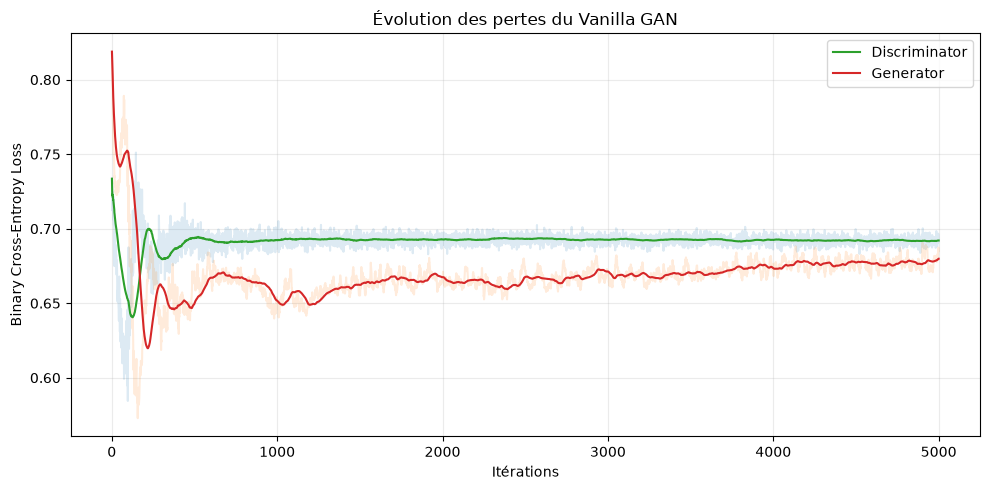

In [21]:
fig, ax = plt.subplots(
    figsize=(10, 5)
)

ax.plot(
    gan_history["Iteration"],
    gan_history["Discriminator_Loss"],
    alpha=0.15
)

ax.plot(
    gan_history["Iteration"],
    gan_history["Generator_Loss"],
    alpha=0.15
)

ax.plot(
    gan_history["Iteration"],
    gan_history["D_Loss_Smooth"],
    label="Discriminator"
)

ax.plot(
    gan_history["Iteration"],
    gan_history["G_Loss_Smooth"],
    label="Generator"
)

ax.set_xlabel("Itérations")
ax.set_ylabel("Binary Cross-Entropy Loss")
ax.set_title(
    "Évolution des pertes du Vanilla GAN"
)

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "gan_training_losses.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
gan_history = pd.DataFrame({
    "Iteration": np.arange(1, N_STEPS + 1),
    "Discriminator_Loss": d_losses,
    "Generator_Loss": g_losses
})

gan_history["D_Loss_Smooth"] = (
    gan_history["Discriminator_Loss"]
    .rolling(
        window=100,
        min_periods=1
    )
    .mean()
)

gan_history["G_Loss_Smooth"] = (
    gan_history["Generator_Loss"]
    .rolling(
        window=100,
        min_periods=1
    )
    .mean()
)

gan_history.head()

,Iteration,Discriminator_Loss,Generator_Loss,D_Loss_Smooth,G_Loss_Smooth
0,1,0.733575,0.818811,0.733575,0.818811
1,2,0.721377,0.812180,0.727476,0.815495
2,3,0.712269,0.804992,0.722407,0.811994
3,4,0.724813,0.797012,0.723008,0.808249
4,5,0.714116,0.787426,0.721230,0.804084


In [19]:
rng = np.random.default_rng(SEED)

d_losses = []
g_losses = []

for step in range(1, N_STEPS + 1):

    indices = rng.integers(
        low=0,
        high=len(real_fraud_array),
        size=BATCH_SIZE
    )

    real_batch = tf.convert_to_tensor(
        real_fraud_array[indices]
    )

    d_loss, g_loss = gan_train_step(
        real_batch
    )

    d_value = float(d_loss.numpy())
    g_value = float(g_loss.numpy())

    d_losses.append(d_value)
    g_losses.append(g_value)

    if (
        np.isnan(d_value)
        or np.isnan(g_value)
        or np.isinf(d_value)
        or np.isinf(g_value)
    ):
        raise RuntimeError(
            f"Instabilité numérique à l'itération {step}"
        )

    if step in SNAPSHOT_STEPS:

        generated_snapshot = generator(
            fixed_noise,
            training=False
        ).numpy()

        snapshots[step] = generated_snapshot.copy()

    if step == 1 or step % 500 == 0:

        print(
            f"Iteration {step:4d}/{N_STEPS} "
            f"| D_loss = {d_value:.4f} "
            f"| G_loss = {g_value:.4f}"
        )

Iteration    1/5000 | D_loss = 0.7336 | G_loss = 0.8188
Iteration  500/5000 | D_loss = 0.6916 | G_loss = 0.6682
Iteration 1000/5000 | D_loss = 0.6992 | G_loss = 0.6511
Iteration 1500/5000 | D_loss = 0.6943 | G_loss = 0.6562
Iteration 2000/5000 | D_loss = 0.6937 | G_loss = 0.6667
Iteration 2500/5000 | D_loss = 0.6920 | G_loss = 0.6724
Iteration 3000/5000 | D_loss = 0.6889 | G_loss = 0.6709
Iteration 3500/5000 | D_loss = 0.6952 | G_loss = 0.6679
Iteration 4000/5000 | D_loss = 0.6970 | G_loss = 0.6717
Iteration 4500/5000 | D_loss = 0.6949 | G_loss = 0.6779
Iteration 5000/5000 | D_loss = 0.6915 | G_loss = 0.6849


In [18]:
snapshot_rng = np.random.default_rng(SEED)

fixed_noise = snapshot_rng.normal(
    size=(331, LATENT_DIM)
).astype(np.float32)

SNAPSHOT_STEPS = [
    1,
    100,
    500,
    1000,
    2500,
    5000
]

snapshots = {}

In [17]:
real_fraud_array = (
    X_real_fraud
    .to_numpy(dtype=np.float32)
)

print(real_fraud_array.shape)

(331, 30)


In [16]:
@tf.function
def gan_train_step(real_batch):

    current_batch_size = tf.shape(real_batch)[0]

    # ----------------------------
    # 1. Entraîner Discriminator
    # ----------------------------

    noise = tf.random.normal(
        shape=(current_batch_size, LATENT_DIM)
    )

    with tf.GradientTape() as d_tape:

        fake_batch = generator(
            noise,
            training=True
        )

        real_prediction = discriminator(
            real_batch,
            training=True
        )

        fake_prediction = discriminator(
            fake_batch,
            training=True
        )

        real_loss = bce(
            tf.ones_like(real_prediction),
            real_prediction
        )

        fake_loss = bce(
            tf.zeros_like(fake_prediction),
            fake_prediction
        )

        d_loss = (
            real_loss + fake_loss
        ) / 2.0

    d_gradients = d_tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    discriminator_optimizer.apply_gradients(
        zip(
            d_gradients,
            discriminator.trainable_variables
        )
    )

    # ----------------------------
    # 2. Entraîner Generator
    # ----------------------------

    noise = tf.random.normal(
        shape=(current_batch_size, LATENT_DIM)
    )

    with tf.GradientTape() as g_tape:

        fake_batch = generator(
            noise,
            training=True
        )

        fake_prediction = discriminator(
            fake_batch,
            training=False
        )

        g_loss = bce(
            tf.ones_like(fake_prediction),
            fake_prediction
        )

    g_gradients = g_tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            g_gradients,
            generator.trainable_variables
        )
    )

    return d_loss, g_loss

In [15]:
bce = keras.losses.BinaryCrossentropy()

generator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE_G,
    beta_1=BETA_1
)

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE_D,
    beta_1=BETA_1
)

In [14]:
test_noise = tf.random.normal(
    shape=(5, LATENT_DIM)
)

test_fake = generator(
    test_noise,
    training=False
)

print("Forme :", test_fake.shape)
print("Minimum :", tf.reduce_min(test_fake).numpy())
print("Maximum :", tf.reduce_max(test_fake).numpy())

Forme : (5, 30)
Minimum : 0.26172096
Maximum : 0.6859078


In [13]:
discriminator = build_discriminator()

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,337 (56.00 KB)

 Trainable params: 14,337 (56.00 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
def build_discriminator():

    model = keras.Sequential(
        [
            layers.Input(shape=(N_FEATURES,)),

            layers.Dense(128),
            layers.LeakyReLU(negative_slope=0.2),
            layers.Dropout(0.30),

            layers.Dense(64),
            layers.LeakyReLU(negative_slope=0.2),
            layers.Dropout(0.30),

            layers.Dense(32),
            layers.LeakyReLU(negative_slope=0.2),

            layers.Dense(
                1,
                activation="sigmoid"
            )
        ],
        name="Discriminator"
    )

    return model

In [11]:
generator = build_generator()

generator.summary()

Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 30)             │         1,950 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,278 (83.12 KB)

 Trainable params: 20,894 (81.62 KB)

 Non-trainable params: 384 (1.50 KB)

In [10]:
def build_generator():

    model = keras.Sequential(
        [
            layers.Input(shape=(LATENT_DIM,)),

            layers.Dense(64),
            layers.LeakyReLU(negative_slope=0.2),
            layers.BatchNormalization(),

            layers.Dense(128),
            layers.LeakyReLU(negative_slope=0.2),
            layers.BatchNormalization(),

            layers.Dense(64),
            layers.LeakyReLU(negative_slope=0.2),

            layers.Dense(
                N_FEATURES,
                activation="sigmoid"
            )
        ],
        name="Generator"
    )

    return model

In [9]:
N_FEATURES = X_real_fraud.shape[1]

LATENT_DIM = 30
BATCH_SIZE = 64
N_STEPS = 5000

LEARNING_RATE_G = 0.0002
LEARNING_RATE_D = 0.0002
BETA_1 = 0.5

print("Nombre de caractéristiques :", N_FEATURES)
print("Dimension du bruit :", LATENT_DIM)
print("Batch size :", BATCH_SIZE)
print("Itérations :", N_STEPS)

Nombre de caractéristiques : 30
Dimension du bruit : 30
Batch size : 64
Itérations : 5000


## Architecture du Vanilla GAN

Le GAN repose sur deux réseaux antagonistes :

**Générateur (Generator)**  
Il reçoit un vecteur aléatoire `z` de dimension 30 et produit une
transaction synthétique possédant 30 caractéristiques.

**Discriminateur (Discriminator)**  
Il reçoit une transaction de 30 caractéristiques et estime si elle
provient des données frauduleuses réelles ou du générateur.

Le générateur cherche progressivement à tromper le discriminateur,
tandis que le discriminateur cherche à distinguer les transactions
réelles des transactions synthétiques.

In [8]:
print(
    "Minimum global des fraudes Train :",
    X_real_fraud.min().min()
)

print(
    "Maximum global des fraudes Train :",
    X_real_fraud.max().max()
)

Minimum global des fraudes Train : 0.0
Maximum global des fraudes Train : 1.0


In [7]:
X_real_fraud = (
    X_train.loc[y_train == 1]
    .reset_index(drop=True)
)

print("Fraudes réelles utilisées par le GAN :", X_real_fraud.shape)

Fraudes réelles utilisées par le GAN : (331, 30)


In [6]:
X_train = pd.read_parquet(
    PROCESSED_DIR / "X_train.parquet"
)

y_train = pd.read_parquet(
    PROCESSED_DIR / "y_train.parquet"
)["Class"]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

X_train : (198608, 30)
y_train : (198608,)


## Chargement des transactions frauduleuses réelles de Train

In [5]:
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
SYNTHETIC_DIR = PROJECT_ROOT / "results" / "synthetic"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [
    FIGURES_DIR,
    METRICS_DIR,
    SYNTHETIC_DIR,
    MODELS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Projet :", PROJECT_ROOT)

Projet : c:\Users\MSI\Desktop\fraud_detection_memoire


In [4]:
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

print("Seed :", SEED)

Seed : 42


In [3]:
print("TensorFlow :", tf.__version__)
print("Keras :", keras.__version__)
print("Devices :", tf.config.list_physical_devices())

TensorFlow : 2.21.0
Keras : 3.15.1
Devices : [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors

from scipy.stats import ks_2samp, wasserstein_distance
from scipy.spatial.distance import pdist

# 05 — Génération de transactions frauduleuses par Vanilla GAN

Ce notebook met en œuvre un réseau génératif adversarial (GAN) afin
d'apprendre la distribution des transactions frauduleuses réelles
présentes dans l'ensemble d'entraînement.

Le GAN est entraîné exclusivement sur les transactions frauduleuses
de Train. Les ensembles de validation et de test ne sont jamais utilisés
pour entraîner le générateur.

Les objectifs sont :

- construire le générateur et le discriminateur ;
- entraîner les deux réseaux de manière adversariale ;
- suivre leurs fonctions de perte pendant 5000 itérations ;
- observer l'évolution des données générées ;
- produire des fraudes synthétiques ;
- évaluer leur fidélité et leur diversité ;
- contrôler les phénomènes de mémorisation et de mode collapse ;
- sauvegarder les modèles et les données synthétiques.